# TP3 — Régression et régularisation

**Cours :** Introduction au Machine Learning — 60 h — Licence 3 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 3 h · **Barème :** 15 points

---

## Objectifs

- Ajuster un OLS et le diagnostiquer.
- Tracer les chemins Ridge et Lasso.
- Choisir lambda par validation croisée.
- Montrer expérimentalement quand la régularisation gagne.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous ».
2. Rendre le notebook exécuté.

## Mode d'emploi

- Exécuter dans l'ordre ; tout tourne sur CPU en moins d'une minute.
- Les cellules **« À vous »** sont évaluées. Graine fixée.

In [1]:
%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
np.random.seed(4112)
print('environnement pret')

environnement pret


## 1. Les données

Jeu **diabetes** (fourni avec scikit-learn) : 442 patients, 10 variables
cliniques, cible = progression de la maladie un an plus tard.

In [2]:
from sklearn.datasets import load_diabetes
X, y = load_diabetes(return_X_y=True, as_frame=True)
print("formes :", X.shape)
print("cible  : moyenne", round(y.mean(), 1), "| ecart-type", round(y.std(), 1))
X.head(3)

formes : (442, 10)
cible  : moyenne 152.1 | ecart-type 77.1


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930


## 2. Découper avant toute transformation

In [3]:
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=4112)
print("entrainement :", Xtr.shape, "| test :", Xte.shape)

entrainement : (331, 10) | test : (111, 10)


## 3. La référence : OLS dans un pipeline

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ols = Pipeline([("sc", StandardScaler()), ("reg", LinearRegression())]).fit(Xtr, ytr)
pred = ols.predict(Xte)
print(f"R2   : {r2_score(yte, pred):.3f}")
print(f"RMSE : {np.sqrt(mean_squared_error(yte, pred)):.2f}")
print(f"MAE  : {mean_absolute_error(yte, pred):.2f}")

R2   : 0.503
RMSE : 53.52
MAE  : 43.37


## 4. Lire les coefficients

In [5]:
coefs = pd.Series(ols.named_steps["reg"].coef_, index=X.columns).sort_values()
print(coefs.round(2).to_string())

s1    -30.81
sex   -11.82
age     0.88
s6      0.97
s3      2.54
s4      7.89
s2     16.05
bp     16.41
bmi    24.10
s5     34.93


## 5. Diagnostiquer les résidus

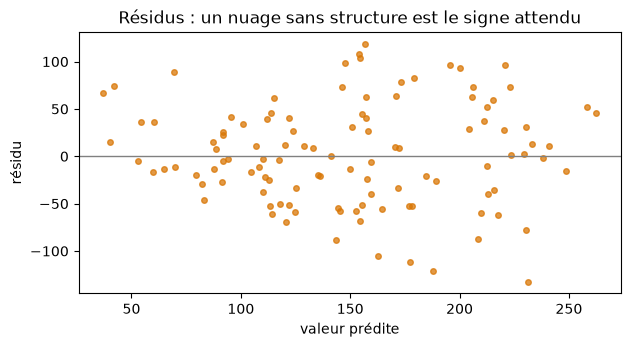

correlation |residu| / prediction : 0.235


In [6]:
res = yte - pred
plt.figure(figsize=(7, 3.4))
plt.scatter(pred, res, s=16, color="#D97706", alpha=.75)
plt.axhline(0, color="grey", lw=1)
plt.xlabel("valeur prédite"); plt.ylabel("résidu")
plt.title("Résidus : un nuage sans structure est le signe attendu")
plt.show()
print("correlation |residu| / prediction :", round(float(np.corrcoef(pred, np.abs(res))[0,1]), 3))

## 6. Ridge et Lasso : les chemins

On fait varier $\lambda$ et on observe les coefficients.

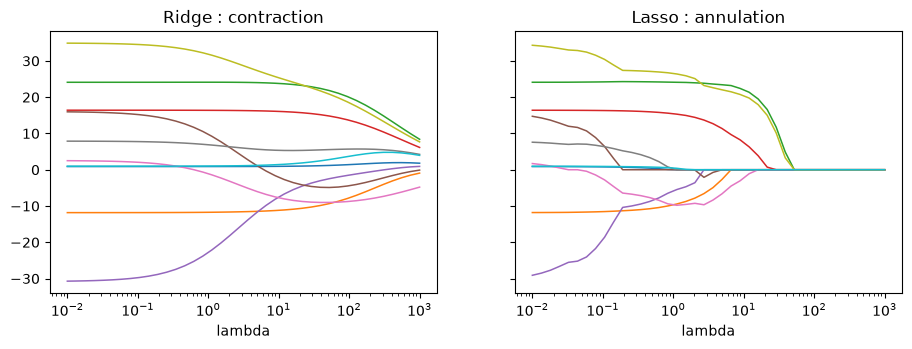

coefficients Lasso non nuls au plus grand lambda : 0


In [7]:
from sklearn.linear_model import Ridge, Lasso

alphas = np.logspace(-2, 3, 40)
Xtr_s = StandardScaler().fit_transform(Xtr)
chemins_r, chemins_l = [], []
for a in alphas:
    chemins_r.append(Ridge(alpha=a).fit(Xtr_s, ytr).coef_)
    chemins_l.append(Lasso(alpha=a, max_iter=20000).fit(Xtr_s, ytr).coef_)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for j in range(X.shape[1]):
    axes[0].semilogx(alphas, np.array(chemins_r)[:, j], lw=1.1)
    axes[1].semilogx(alphas, np.array(chemins_l)[:, j], lw=1.1)
axes[0].set_title("Ridge : contraction"); axes[1].set_title("Lasso : annulation")
for ax in axes: ax.set_xlabel("lambda")
plt.show()
print("coefficients Lasso non nuls au plus grand lambda :",
      int((np.abs(chemins_l[-1]) > 1e-8).sum()))

## 7. Choisir $\lambda$ par validation croisée

In [8]:
from sklearn.linear_model import RidgeCV
modele = Pipeline([("sc", StandardScaler()),
                   ("ridge", RidgeCV(alphas=np.logspace(-2, 3, 40), cv=5))]).fit(Xtr, ytr)
print("lambda retenu :", round(float(modele.named_steps["ridge"].alpha_), 3))
print("RMSE test     :", round(float(np.sqrt(mean_squared_error(yte, modele.predict(Xte)))), 2))

lambda retenu : 28.943
RMSE test     : 53.71


## 8. Grande dimension : quand la régularisation change tout

150 variables pour 120 observations, dont 8 seulement sont informatives.

In [9]:
rng = np.random.default_rng(4112)
n, p, k = 120, 150, 8
Xg = rng.normal(size=(n, p))
beta = np.zeros(p); beta[:k] = rng.uniform(1.5, 3.0, k) * rng.choice([-1, 1], k)
yg = Xg @ beta + rng.normal(0, 1.0, n)
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg, yg, test_size=.3, random_state=4112)

def rmse(m):
    mod = Pipeline([("sc", StandardScaler()), ("m", m)]).fit(Xg_tr, yg_tr)
    return round(float(np.sqrt(mean_squared_error(yg_te, mod.predict(Xg_te)))), 2), mod

r_ols, _ = rmse(LinearRegression())
r_ridge, _ = rmse(RidgeCV(alphas=np.logspace(-2, 4, 40)))
r_lasso, m_lasso = rmse(Lasso(alpha=0.3, max_iter=50000))
print(f"OLS   : {r_ols}")
print(f"Ridge : {r_ridge}")
print(f"Lasso : {r_lasso}")
print("coefficients non nuls :", int((np.abs(m_lasso.named_steps['m'].coef_) > 1e-6).sum()))

OLS   : 6.04
Ridge : 6.04
Lasso : 1.48
coefficients non nuls : 11


## 9. À vous (noté)

**1.** Ajoutez une variable $x^2$ (carré d'une des colonnes) : le $R^2$ de test
augmente-t-il ? Que se passe-t-il si vous ajoutez tous les carrés ?

**2.** Sur le jeu de grande dimension, faites varier l'alpha du Lasso
(0,01 ; 0,1 ; 1 ; 10). Combien de coefficients restent non nuls à chaque fois ?

**3.** Expliquez en deux phrases pourquoi Ridge n'apporte rien sur le jeu du
diabète mais pourrait aider si deux variables étaient corrélées à 0,99.

In [10]:
# ---- A VOUS ----
# 1)
# 2)
# 3)

## 10. Ce qu'il faut retenir

| Geste | Pourquoi |
|---|---|
| OLS d'abord | c'est la référence à battre |
| standardiser dans le pipeline | sinon la pénalité dépend des unités |
| régulariser si p grand ou colinéaire | sinon l'OLS suffit |
| choisir lambda par CV | le test ne sert qu'une fois |
| lire les résidus | ils disent ce que le modèle n'a pas capté |